# Introduction

## What is EDA?
The 1st stage with dealing with data targets to explore data and help finiding the best ways to deal with it.\
It helps finding trends and upnormal patterens.

### Methods used:\
- Statistical Methods
- Data Visualization

### Why it is importatnt?
It gives a generel view on the data before taking any dessision or making any assumptions. In addition to understanding the patterens and mistakes in the data.

## Concepts Related to EDA

The difference between Exploratary Data Analysis and Explanatory Data Analysis\
 \
<img src="./related_concepts.png" alt="Related Concepts" width="500">

Storytelling\
 \
<img src="./storytelling.png" alt="Storytelling" width="300">
 \
It's a very important skill that aims to drive the most important insights and foundings to the audiance.\
It should be simple, clear, and understandable to the audiance directly.



# Importing and Downloading the Dataset

In [1]:
# libs used
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
tips = sns.load_dataset('tips') # downloading the dataset
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


# EDA Steps

- Knowing the no. rows and columns (shape): to know if the data is enough or not.
- Displaying info: to know the data type of each column and the missing values in each column.
- Printing the top 5 and the bottom 5 rows to have a quick look on the data.
- Displaying Numarical and Categorical Statistical Summaries: to have a good background about the data in each column.
  - Numarical: count, mean, std, min, 25%, 50%, 75%, and max.
  - Categorical: count, unique, top/mode, freq of top/mode. In addition to values_count of each column.
- Uni/Bi/Multi Variate Analysis.

In [3]:
# rows and cols and the data type of each in addition to the missing values
tips.info()
# 7 columns (4 categorical, 2 float, and 1 int), 244 rows, no missing values in any column.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


In [4]:
tips.head() # 1st 5 rows
# Time represent the meal
# size is the no. people on the table
# sex is Male/Female.
# Smoker is Yes or No
# Day use only the 1st 3 letters

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [5]:
tips.tail() # last 5 rows

,total_bill,tip,sex,smoker,day,time,size
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2
243,18.78,3.00,Female,No,Thur,Dinner,2


In [6]:
tips.describe() # numarical statistical summary
# the range or the values is much different, we need to normalize that later
# ..... describing each column such as the std in the total_bill

,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


In [7]:
tips.describe(exclude= 'number') # categorical statistical summary
# we have inbalanse in all of the categorical variables

,sex,smoker,day,time
count,244,244,244,244
unique,2,2,4,2
top,Male,No,Sat,Dinner
freq,157,151,87,176


# Univariate Analysis

Describing a sigle varible in depth.\
For Numarical: Histogram and Density Plots\
For Categorical: Bar and Pie Plots

### Numarical

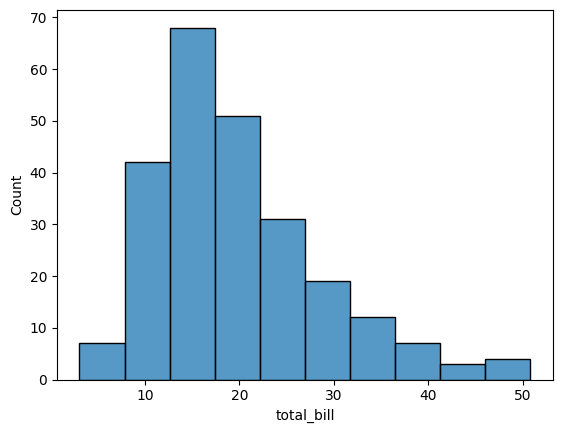

In [8]:
sns.histplot(data=tips, x="total_bill", bins=10); # a histogram
# right tail

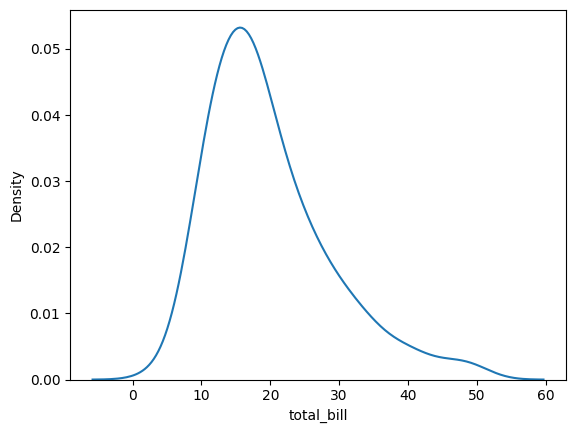

In [9]:
sns.kdeplot(data=tips, x="total_bill"); # density plot
# same insight

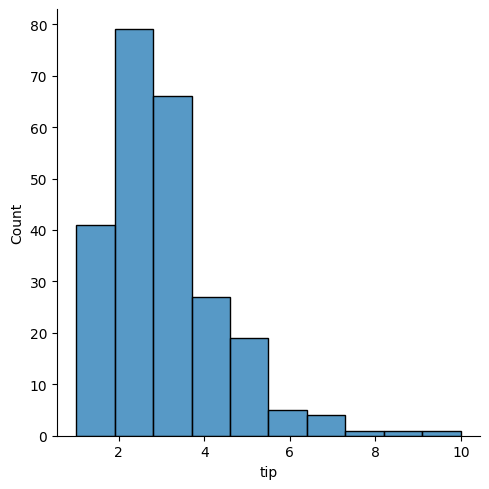

In [10]:
sns.displot(data=tips, x="tip", bins=10); # a histogram using displot
# we have a right side tail and seems like outlayer

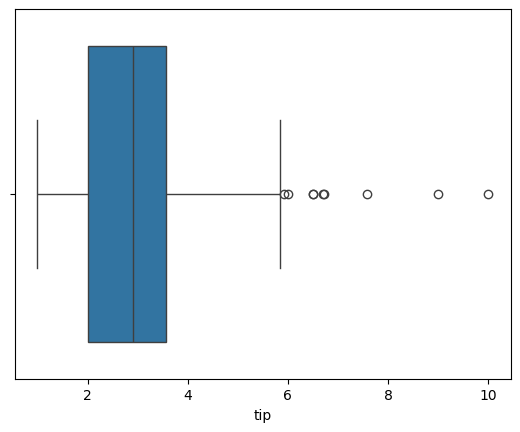

In [11]:
sns.boxplot(data=tips, x="tip"); # yah, a lot of outlayers in the right side

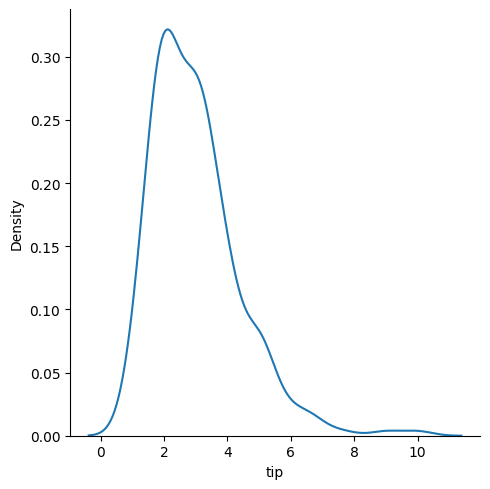

In [12]:
sns.displot(data=tips, x="tip", kind='kde'); # a density plot using displot

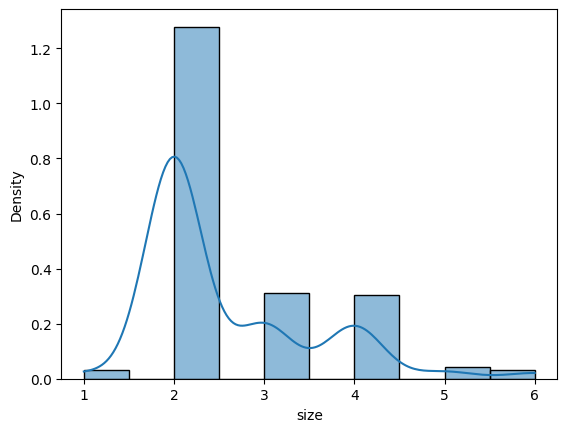

In [13]:
sns.histplot(data=tips, x="size", kde=True, stat="density", bins=10); # both on top of each other.

### Categorical

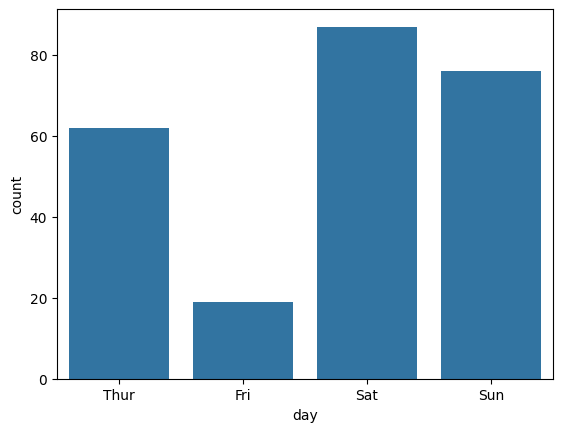

In [14]:
sns.countplot(data=tips, x="day"); # a bar plot
# the Friday has much lewer samples than the others

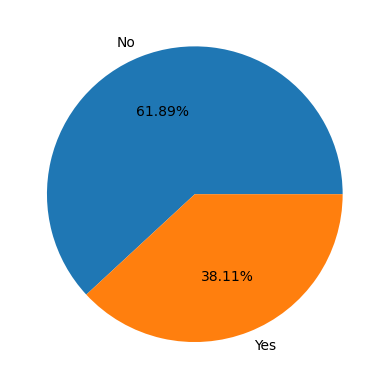

In [15]:
plt.pie(tips["smoker"].value_counts(), labels=tips["smoker"].value_counts().index, autopct="%1.2f%%"); # a pie plot
# inbalanced data

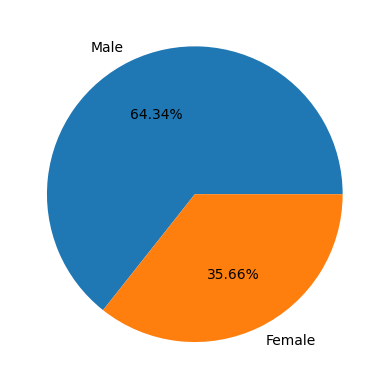

In [16]:
plt.pie(tips["sex"].value_counts(), labels=tips["sex"].value_counts().index, autopct="%1.2f%%"); # a pie plot
# inbalanced data

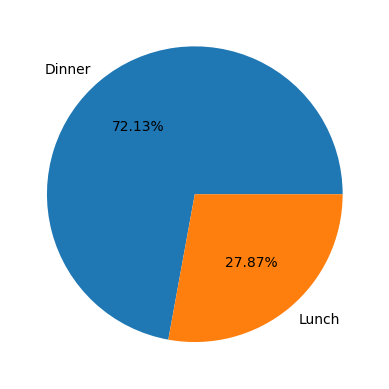

In [17]:
plt.pie(tips["time"].value_counts(), labels=tips["time"].value_counts().index, autopct="%1.2f%%"); # a pie plot
# inbalanced data

# Bivariate Analysis

Describing the relationship between 2 variables in depth and detect patterens.\
Numarical VS. Numarical: Line or Scatter Plots\
Categorical VS. Categorical: Clusterd Histogram or Clustered Bar\
Categorical VS. Numarical: Clustered Histogram, Clustered Bar, Side-by-side Bar, Violin Plot, Swarm Plot, Box plot, and Scatter Plot

### Numrical vs. Numarical

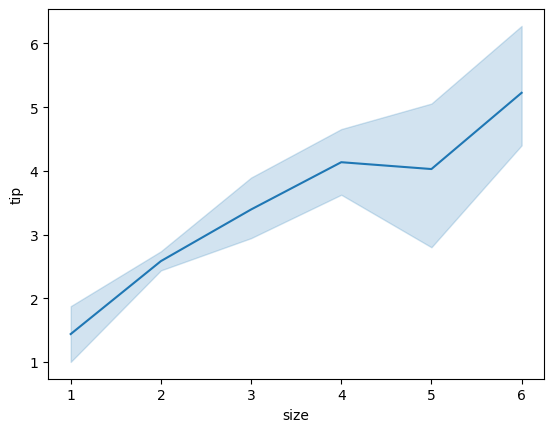

In [18]:
sns.lineplot(data=tips, x="size", y="tip"); # a line plot
# as the no. peaple on the teble increases, the tip increases

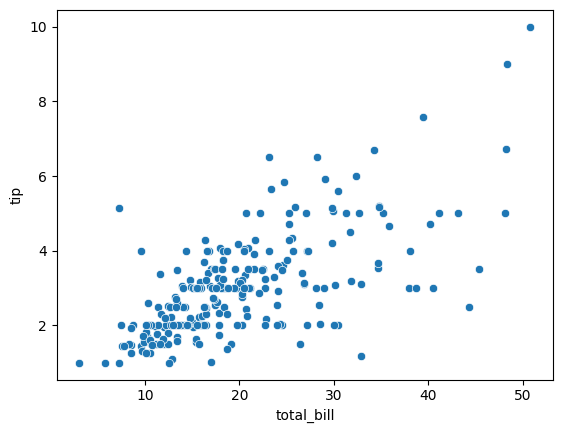

In [19]:
sns.scatterplot(data=tips, x="total_bill", y="tip"); # a scatter plot
# there is a weak positive linear corealtion between the totabl bill and the tip

### Catigorical vs. Categorical

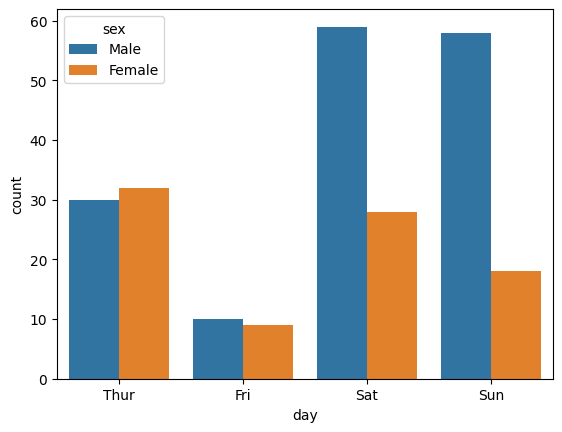

In [20]:
sns.countplot(data=tips, x="day", hue="sex"); # clustered/side-by-side bar
# the inbalance in the sex class is on Saterday and Sunday only, they are balanced in the other days

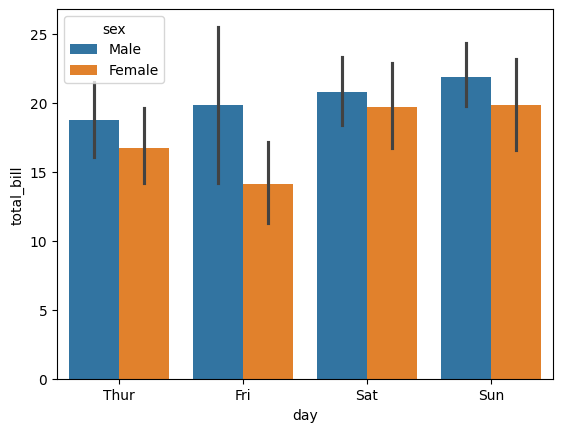

In [21]:
sns.barplot(data=tips, x="day", y="total_bill", hue="sex"); # stacked bar

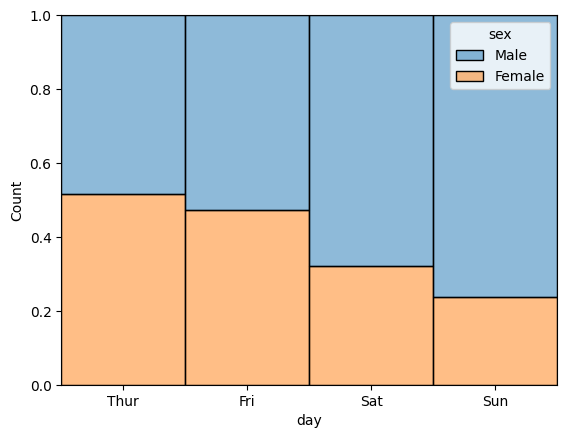

In [22]:
sns.histplot(data=tips, x="day", hue="sex", alpha=0.5, multiple="fill"); # stacked bar
# you can try these: multiple= "layer" default, "dodge", "stack", "fill"

### Categorical vs. Numarical

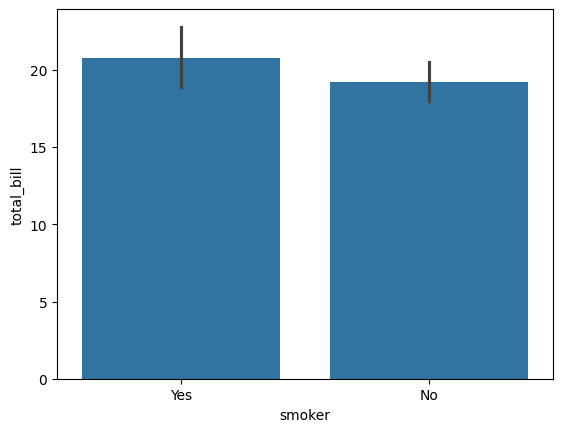

In [23]:
sns.barplot(data=tips, x="smoker", y="total_bill"); # box plot
# the mean of total bill is simi balanced between the smokers and non-smokers but non-smoker have a slightly more total bills.

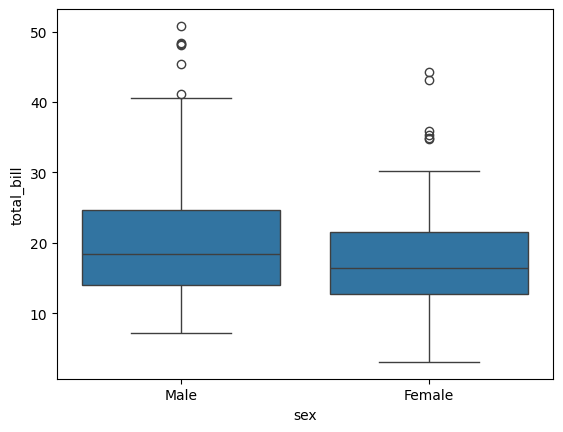

In [24]:
sns.boxplot(data=tips, x="sex", y="total_bill"); # box plot
# males have more total bills in general

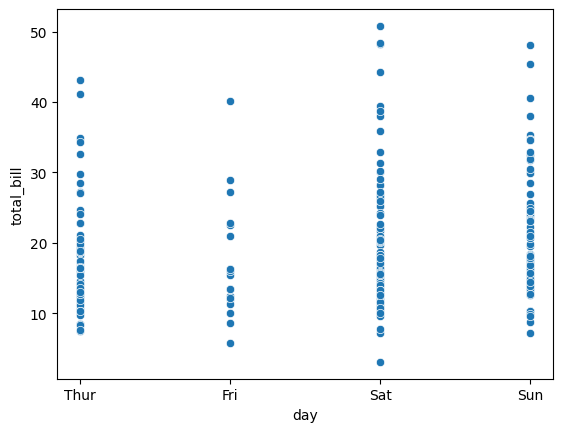

In [25]:
sns.scatterplot(data=tips, x="day", y="total_bill"); # box plot
# total bills are higher in sat than others and lewer in fri day (note: friday has much lewer frequences in the data than others)

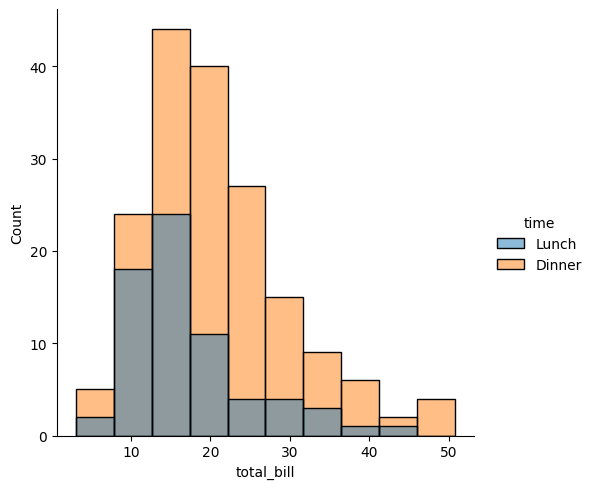

In [26]:
sns.displot(data=tips, x="total_bill", hue="time", bins=10); # histogram on top of each other
# the dinner have much more total bills than lunch.

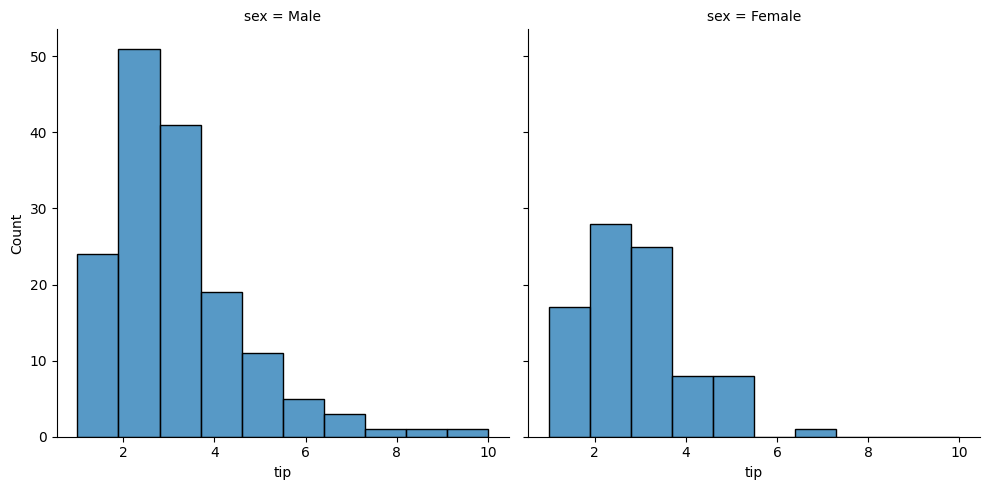

In [27]:
sns.displot(data=tips, x="tip", col="sex", bins=10); # or splitted
# males have give more tips than females

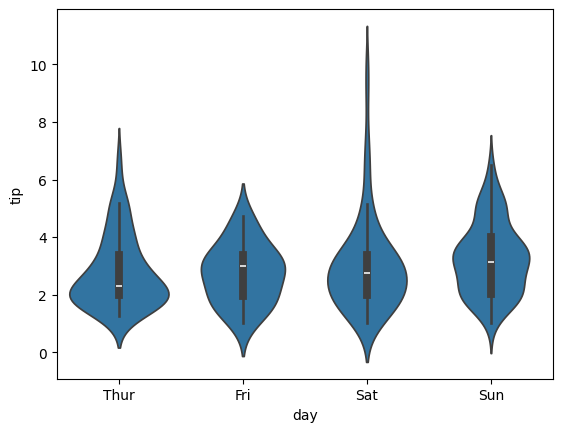

In [28]:
sns.violinplot(data=tips, x="day", y="tip"); # violin plot
# Saterday has a lot of outlayers and more varation than others. Sunday is the one with more consistent tips over the others

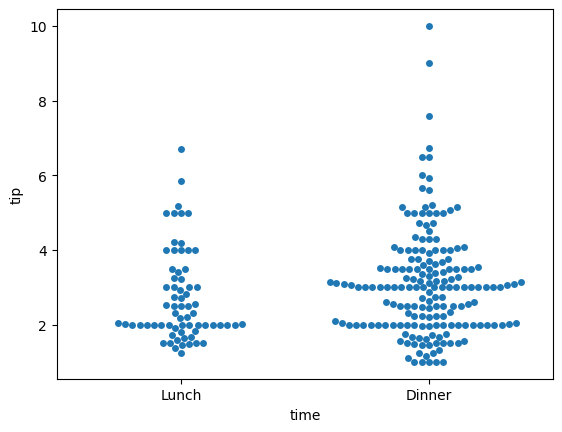

In [29]:
sns.swarmplot(data=tips, x="time", y="tip"); # swarm plot
# dinner has more tips than lunch. The tip has a low variation in general and specially in dinner. in addition to some outlayers

# Multi-variate Analysis

Used to detect patterens between more than 2 variables.\
Use simple charts such as Bar, Scatter, and Line plots. In addition to more complex charts such as the pairs heatmap.\
Use more complex techniques such as scatter analysis and linear/logistic regression.

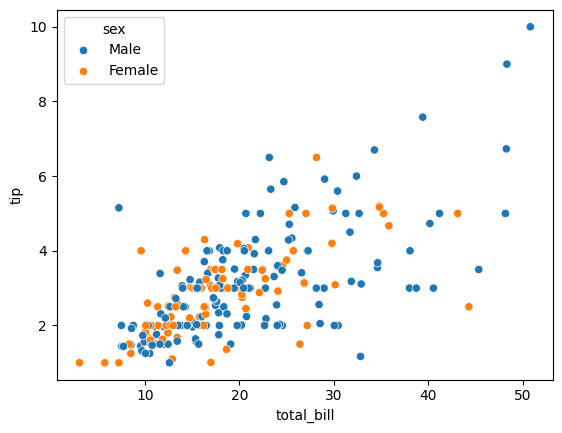

In [30]:
sns.scatterplot(data=tips, x="total_bill", y="tip", hue="sex"); # scatter plot
# as the total bill increases, the bill increases, and males give more than females

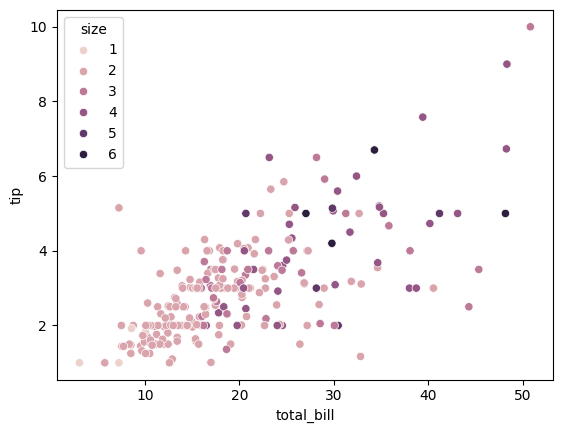

In [31]:
sns.scatterplot(data=tips, x="total_bill", y="tip", hue="size"); # scatter plot
# as the number of pp increases, the total_bill increases, and the tip increases too

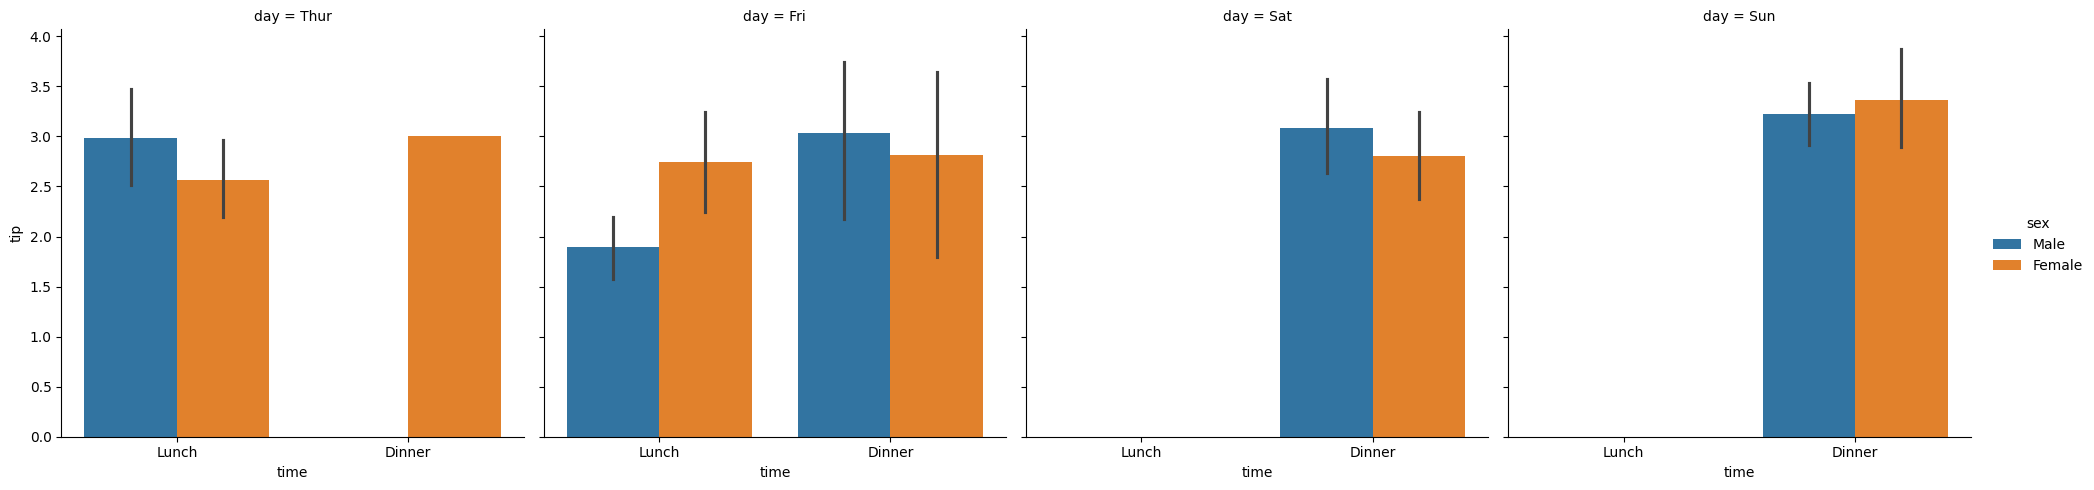

In [32]:
sns.catplot(data=tips, x="time", y="tip", hue="sex", col="day", kind='bar'); # bar plot
# no males come on dinner on Thuresday
# ... a lot of insights here such as no lunch on Saterday and Sunday

**Written by:**\
Abobaker Ahmed. [LinkedIn](https://www.linkedin.com/in/abobaker-ahmed/)